## Celula 1: Importuri necesare

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter

# Setul de date folosit. Pentru rularea a doua:
# DATASET = 'run_2026_06/dataset_final.csv'
DATASET = 'dataset_final.csv'


## Celula 2: Logica de separare pe sesiuni și scalare

In [2]:
def load_and_split_merged(csv_path):
    """
    Încarcă fișierul centralizat și face un split secvențial (80/20) 
    pentru fiecare combinație de clasă și viteză PWM.
    Astfel modelul vede toate vitezele, uidar păstrăm validarea curată, fără scurgeri de informații.
    """
    df = pd.read_csv(csv_path)
    
    train_list = []
    test_list = []
    
    # Presupunem că fișierul are coloanele 'label' și 'pwm_speed'
    # Grupăm datele pentru a procesa fiecare scenariu/turație individual
    for (label, pwm), group in df.groupby(['label', 'pwm_speed']):
        # Nu amestecăm rândurile! Tăiem pur și simplu secvența cronologică în două.
        split_idx = int(len(group) * 0.8)
        
        train_list.append(group.iloc[:split_idx])
        test_list.append(group.iloc[split_idx:])
        
    train_df = pd.concat(train_list, ignore_index=True)
    test_df = pd.concat(test_list, ignore_index=True)
    
    return train_df, test_df
train_df, test_df = load_and_split_merged(DATASET)
# Rulare:
# train_df, test_df = load_and_split_merged('calea_catre_fisierul_tau_mare.csv')

## Celula 3: Preprocesarea și crearea ferestrelor (Window Slicing)

In [4]:
WINDOW_SIZE = 128
STEP_SIZE = 64
FEATURE_COLUMNS = ['ax', 'ay', 'az', 'gx', 'gy', 'gz'] # Adaugă 'temp' dacă e relevant
LABEL_COLUMN = 'label'

# Extragem datele brute
X_train_raw = train_df[FEATURE_COLUMNS]
y_train_raw = train_df[LABEL_COLUMN]
X_test_raw = test_df[FEATURE_COLUMNS]
y_test_raw = test_df[LABEL_COLUMN]

# Standardizare calculată STRICT pe setul de antrenare
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=FEATURE_COLUMNS)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_raw), columns=FEATURE_COLUMNS)

def create_windows(X, y, window_size, step_size):
    Xs, ys = [], []
    for i in range(0, len(X) - window_size, step_size):
        v = X.iloc[i:(i + window_size)].values
        label = Counter(y.iloc[i:(i + window_size)]).most_common(1)[0][0]
        Xs.append(v)
        ys.append(label)
    return np.array(Xs), np.array(ys)

X_train, y_train = create_windows(X_train_scaled, y_train_raw, WINDOW_SIZE, STEP_SIZE)
X_test, y_test = create_windows(X_test_scaled, y_test_raw, WINDOW_SIZE, STEP_SIZE)

print(f"Dimensiune X_train: {X_train.shape}")
print(f"Dimensiune X_test: {X_test.shape}")

Dimensiune X_train: (6727, 128, 6)
Dimensiune X_test: (1681, 128, 6)


## Celula 4: Calcularea ponderilor pentru clase (Class Weights)

In [6]:
# Calculăm ponderile pentru a echilibra clasa 0
class_weights_array = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(class_weights_array))

print("Ponderile claselor:", class_weights)

Ponderile claselor: {0: np.float64(5.001486988847583), 1: np.float64(0.8330650154798762), 2: np.float64(0.8330650154798762), 3: np.float64(0.8330650154798762), 4: np.float64(0.8340979541227527)}


# CNN1D
## Celula 5: Definirea și compilarea modelului

In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_tiny_cnn1d(input_shape, num_classes):
    model = models.Sequential([
        # Strat de intrare
        layers.InputLayer(input_shape=input_shape),
        
        # Primul bloc convoluțional pentru extragerea trăsăturilor de bază
        layers.Conv1D(filters=16, kernel_size=3, activation='relu'),
        layers.MaxPooling1D(pool_size=2),
        
        # Al doilea bloc convoluțional pentru tipare mai complexe
        layers.Conv1D(filters=32, kernel_size=3, activation='relu'),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(0.3), # Previne memorarea datelor (overfitting)
        
        # Reducem dimensiunile masiv pentru eficiență pe microcontroler
        layers.GlobalAveragePooling1D(),
        
        # Strat dens pentru decizie
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),
        
        # Stratul de ieșire cu 5 neuroni (pentru cele 5 clase simulate)
        layers.Dense(num_classes, activation='softmax')
    ])
    
    model.compile(optimizer='adam', 
                  loss='sparse_categorical_crossentropy', 
                  metrics=['accuracy'])
    return model

# Extragem forma intrării din datele noastre (128, 6)
input_shape = (X_train.shape[1], X_train.shape[2])
num_classes = len(np.unique(y_train))

model = build_tiny_cnn1d(input_shape, num_classes)
model.summary()

c:\Users\Cristi\Desktop\Licenta\Model_ML_BASELINE\.venv\Lib\site-packages\keras\src\layers\core\input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 126, 16)        │           304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 63, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 61, 32)         │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,093 (12.08 KB)

 Trainable params: 3,093 (12.08 KB)

 Non-trainable params: 0 (0.00 B)

## Celula 6: Antrenarea Modelului

In [7]:
# Parametri de antrenare
EPOCHS = 30
BATCH_SIZE = 32

print("Începem antrenarea modelului...")
history = model.fit(
    X_train, 
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_test, y_test),
    class_weight=class_weights # Aplicăm ponderile calculate anterior
)

Începem antrenarea modelului...
Epoch 1/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7474 - loss: 0.7161 - val_accuracy: 0.9827 - val_loss: 0.1674
Epoch 2/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9799 - loss: 0.0959 - val_accuracy: 0.9964 - val_loss: 0.0220
Epoch 3/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9918 - loss: 0.0330 - val_accuracy: 0.9976 - val_loss: 0.0107
Epoch 4/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9961 - loss: 0.0192 - val_accuracy: 0.9988 - val_loss: 0.0065
Epoch 5/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9969 - loss: 0.0145 - val_accuracy: 0.9982 - val_loss: 0.0060
Epoch 6/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9976 - loss: 0.0104 - val_accuracy: 0.9982 - val_loss: 0.0057
Epoch 7/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9976 - loss: 0.0082 - val_accuracy: 0.9976 - val_loss: 0.0071
Epoch 8/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9976 -

In [10]:
# Salvarea modelului original Keras (necuantizat, float32)
# Folosim formatul nativ .keras (recomandat de versiunile noi de TensorFlow)
nume_model_keras = "model_cnn1d_original.keras"
model.save(nume_model_keras)
print(f"Modelul original a fost salvat ca: {nume_model_keras}")

# (Opțional, dar recomandat) Salvarea parametrilor scaler-ului
# Vei avea nevoie de mediile (mean_) și deviațiile standard (scale_) în codul C++!
print("\nParametrii pentru StandardScaler de copiat în C++:")
print("float means[] = {", ", ".join([f"{x:.6f}" for x in scaler.mean_]), "};")
print("float scales[] = {", ", ".join([f"{x:.6f}" for x in scaler.scale_]), "};")

Modelul original a fost salvat ca: model_cnn1d_original.keras

Parametrii pentru StandardScaler de copiat în C++:
float means[] = { 0.163085, 1.257205, -10.624784, -0.082103, 0.021795, -0.010438 };
float scales[] = { 0.322586, 0.400106, 0.261893, 0.023412, 0.030094, 0.005760 };


# CNN 2D
## Celula 7: Implementarea modelului CNN 2D

In [17]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Extragem forma intrării din datele noastre (128, 6)
input_shape = (X_train.shape[1], X_train.shape[2])
num_classes = len(np.unique(y_train))
# Parametri de antrenare
EPOCHS = 30
BATCH_SIZE = 32
# 1. Remodelarea datelor pentru CNN 2D: adăugăm dimensiunea canalului la final
# Noua formă va fi: (Eșantioane, Pași de timp, Caracteristici, Canal) -> (N, 128, 6, 1)
X_train_2d = np.expand_dims(X_train, axis=-1)
X_test_2d = np.expand_dims(X_test, axis=-1)

print(f"Dimensiune X_train 2D: {X_train_2d.shape}")

def build_cnn2d(input_shape, num_classes):
    model = models.Sequential([
        layers.InputLayer(input_shape=input_shape),
        
        # Folosim padding='same' pentru a nu reduce prea rapid dimensiunea de 6 caracteristici
        layers.Conv2D(16, kernel_size=(3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D(pool_size=(2, 2), padding='same'),
        
        layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D(pool_size=(2, 2), padding='same'),
        layers.Dropout(0.3),
        
        layers.GlobalAveragePooling2D(),
        
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])
    
    model.compile(optimizer='adam', 
                  loss='sparse_categorical_crossentropy', 
                  metrics=['accuracy'])
    return model

input_shape_2d = (X_train_2d.shape[1], X_train_2d.shape[2], X_train_2d.shape[3])
model_2d = build_cnn2d(input_shape_2d, num_classes)

print("\nAntrenăm modelul CNN 2D...")
history_2d = model_2d.fit(
    X_train_2d, y_train,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_data=(X_test_2d, y_test),
    class_weight=class_weights,
    verbose=1 # Setează 0 dacă vrei să ascunzi log-ul detaliat
)

Dimensiune X_train 2D: (6727, 128, 6, 1)

Antrenăm modelul CNN 2D...
Epoch 1/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6169 - loss: 0.9270 - val_accuracy: 0.9012 - val_loss: 0.3444
Epoch 2/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9020 - loss: 0.2430 - val_accuracy: 0.9673 - val_loss: 0.1160
Epoch 3/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9608 - loss: 0.1111 - val_accuracy: 0.9893 - val_loss: 0.0585
Epoch 4/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9820 - loss: 0.0604 - val_accuracy: 0.9982 - val_loss: 0.0200
Epoch 5/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9899 - loss: 0.0372 - val_accuracy: 0.9982 - val_loss: 0.0137
Epoch 6/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9906 - loss: 0.0285 - val_accuracy: 0.9941 - val_loss: 0.0249
Epoch 7/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9932 - loss: 0.0231 - val_accuracy: 0.9982 - val_loss: 0.0119
Epoch 8/30
211/211 ━━━━━━━━━━━━━━━━

# CNN 3D
## Celula 8: Implementarea modelului CNN 3D

In [18]:
# 1. Remodelarea datelor pentru CNN 3D
# Din (N, 128, 6) transformăm în (N, 128, 2, 3, 1)
# 2 senzori (accel, gyro) x 3 axe (x, y, z) x 1 canal
X_train_3d = X_train.reshape(-1, 128, 2, 3, 1)
X_test_3d = X_test.reshape(-1, 128, 2, 3, 1)

print(f"Dimensiune X_train 3D: {X_train_3d.shape}")

def build_cnn3d(input_shape, num_classes):
    model = models.Sequential([
        layers.InputLayer(input_shape=input_shape),
        
        # Filtru 3D care "scanează" timpul, senzorii și axele simultan
        layers.Conv3D(16, kernel_size=(3, 2, 2), activation='relu', padding='same'),
        # Pooling asimetric: reducem dimensiunea pe axa timpului, dar o păstrăm intactă pe senzori/axe
        layers.MaxPooling3D(pool_size=(2, 1, 1), padding='same'),
        
        layers.Conv3D(32, kernel_size=(3, 2, 2), activation='relu', padding='same'),
        layers.MaxPooling3D(pool_size=(2, 1, 1), padding='same'),
        layers.Dropout(0.3),
        
        layers.GlobalAveragePooling3D(),
        
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])
    
    model.compile(optimizer='adam', 
                  loss='sparse_categorical_crossentropy', 
                  metrics=['accuracy'])
    return model

input_shape_3d = (X_train_3d.shape[1], X_train_3d.shape[2], X_train_3d.shape[3], X_train_3d.shape[4])
model_3d = build_cnn3d(input_shape_3d, num_classes)

print("\nAntrenăm modelul CNN 3D...")
history_3d = model_3d.fit(
    X_train_3d, y_train,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_data=(X_test_3d, y_test),
    class_weight=class_weights,
    verbose=1
)

Dimensiune X_train 3D: (6727, 128, 2, 3, 1)

Antrenăm modelul CNN 3D...
Epoch 1/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.5097 - loss: 1.0783 - val_accuracy: 0.8269 - val_loss: 0.6204
Epoch 2/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.7978 - loss: 0.4377 - val_accuracy: 0.8959 - val_loss: 0.3008
Epoch 3/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8736 - loss: 0.2791 - val_accuracy: 0.9358 - val_loss: 0.1911
Epoch 4/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9144 - loss: 0.2104 - val_accuracy: 0.9554 - val_loss: 0.1349
Epoch 5/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9385 - loss: 0.1556 - val_accuracy: 0.9833 - val_loss: 0.0758
Epoch 6/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9569 - loss: 0.1166 - val_accuracy: 0.9905 - val_loss: 0.0542
Epoch 7/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9645 - loss: 0.1005 - val_accuracy: 0.9952 - val_loss: 0.0320
Epoch 8/30
211/211 ━━━━━━

# Codul Python: Conversia TFLite și generarea fișierului Header (.h)

In [12]:
import tensorflow as tf
import numpy as np

# 1. Definim setul de date reprezentativ pentru calibrarea cuantizării Int8
def representative_dataset():
    for i in range(500):
        # Keras/TFLite așteaptă forma (batch_size, timesteps, features)
        yield [X_train[i:i+1].astype(np.float32)]

print("Inițializăm convertorul TensorFlow Lite...")
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# 2. Setăm optimizările stricte pentru Edge Computing
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset

# Restricționăm operațiunile doar la cele suportate de TensorFlow Lite for Microcontrollers (int8)
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]

# Forțăm intrarea și ieșirea să fie exclusiv int8
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

print("Convertim și cuantizăm modelul...")
tflite_quant_model = converter.convert()

# 3. Exportăm modelul sub formă de Array C++ (Header file)
nume_variabila_c = "cnn1d_int8_model" 
nume_fisier_h = "model_cnn1d_int8.h"

def hex_to_c_array(hex_data, var_name):
    c_str = f"// Fişier generat automat pentru ESP32 (TensorFlow Lite Micro)\n"
    c_str += f"// Model: CNN 1D, Cuantizare: Int8, Intrari: 6 (ax, ay, az, gx, gy, gz)\n"
    c_str += f"#include <Arduino.h>\n\n"
    # Alinierea memoriei (alignas) este critică pentru a evita erori de citire pe procesoarele Xtensa
    c_str += f"alignas(8) const unsigned char {var_name}[] = {{\n"
    
    hex_array = [f"0x{b:02x}" for b in hex_data]
    for i in range(0, len(hex_array), 12):
        c_str += "  " + ", ".join(hex_array[i:i+12]) + ",\n"
    c_str += "};\n\n"
    c_str += f"const unsigned int {var_name}_len = {len(hex_data)};\n"
    return c_str

# CORECtIE AICI: Specificăm encoding="utf-8" pentru a suporta diacriticele
with open(nume_fisier_h, "w", encoding="utf-8") as f:
    f.write(hex_to_c_array(tflite_quant_model, nume_variabila_c))

print(f"\nSUCCESS! Modelul a fost exportat ca array C în '{nume_fisier_h}'.")
print(f"Dimensiunea memoriei modelului cuantizat: {len(tflite_quant_model)} bytes.")

Inițializăm convertorul TensorFlow Lite...
Convertim și cuantizăm modelul...
INFO:tensorflow:Assets written to: C:\Users\Cristi\AppData\Local\Temp\tmp34qewvnp\assets


INFO:tensorflow:Assets written to: C:\Users\Cristi\AppData\Local\Temp\tmp34qewvnp\assets


Saved artifact at 'C:\Users\Cristi\AppData\Local\Temp\tmp34qewvnp'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 6), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  2156753661264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2156753662032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2156753662800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2156753662608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2156753663184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2156753663376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2156753663952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2156753659728: TensorSpec(shape=(), dtype=tf.resource, name=None)


c:\Users\Cristi\Desktop\Licenta\Model_ML_BASELINE\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(



SUCCESS! Modelul a fost exportat ca array C în 'model_cnn1d_int8.h'.
Dimensiunea memoriei modelului cuantizat: 11560 bytes.


# Baseline Stupid


=== REZULTATE BASELINE CLASIC (FĂRĂ ML) ===

              precision    recall  f1-score   support

      Repaus       1.00      1.00      1.00       336
      Normal       0.25      1.00      0.40      2019
Dezechilibru       0.00      0.00      0.00      2019
     Frecare       1.00      0.00      0.00      2019
      Slabit       0.00      0.00      0.00      2018

    accuracy                           0.28      8411
   macro avg       0.45      0.40      0.28      8411
weighted avg       0.34      0.28      0.14      8411



c:\Users\Cristi\Desktop\Licenta\Model_ML_BASELINE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Cristi\Desktop\Licenta\Model_ML_BASELINE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Cristi\Desktop\Licenta\Model_ML_BASELINE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(

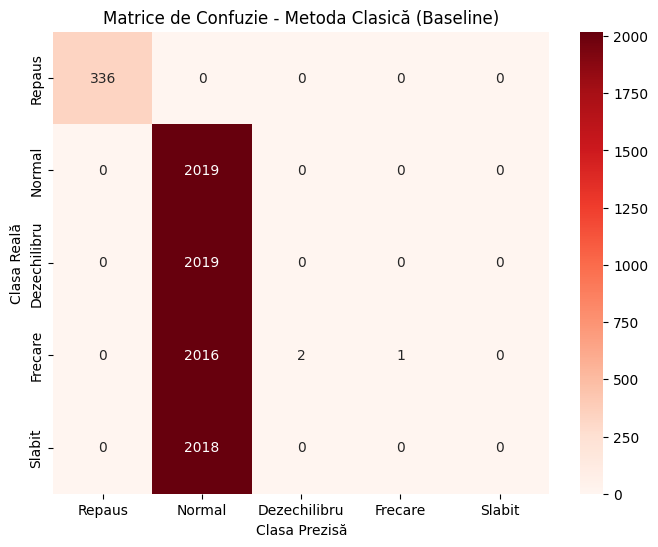

In [7]:
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Încărcăm datele
df = pd.read_csv('dataset_final.csv')

# 2. Definim funcția Baseline (Sistem Expert Clasic cu Praguri IF/ELSE)
# Vom folosi deviația standard (variabilitatea) pe axa Z și axa X într-o fereastră mică (ex. 64 eșantioane)
def baseline_predict(window_df):
    std_z = window_df['az'].std()
    std_x = window_df['ax'].std()
    
    # Praguri deduse euristic (modifică-le dacă vrei să încerci să-l "optimizezi")
    if std_z < 0.05 and std_x < 0.05:
        return 0  # Repaus (Aproape nicio mișcare)
    elif std_z > 5.0 or std_x > 5.0:
        return 3  # Dezechilibru (Vibrații extreme)
    elif std_z > 2.0:
        return 4  # Fixare slabă (Zdruncinături mari pe Z)
    elif std_x > 1.5:
        return 2  # Frecare
    else:
        return 1  # Normal

# 3. Aplicăm Baseline-ul pe ferestre glisante
window_size = 64
y_true = []
y_pred_baseline = []

for i in range(0, len(df) - window_size, window_size):
    window = df.iloc[i : i + window_size]
    # Eticheta reală este majoritatea din fereastră
    actual_label = window['label'].value_counts().idxmax()
    
    # Predicția clasică
    pred_label = baseline_predict(window)
    
    y_true.append(actual_label)
    y_pred_baseline.append(pred_label)

# 4. Afișăm rezultatele pentru a le compara cu CNN-ul
class_names = ['Repaus', 'Normal', 'Dezechilibru', 'Frecare', 'Slabit']
print("=== REZULTATE BASELINE CLASIC (FĂRĂ ML) ===\n")
print(classification_report(y_true, y_pred_baseline, target_names=class_names))

# Matrice de confuzie Baseline
cm = confusion_matrix(y_true, y_pred_baseline)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=class_names, yticklabels=class_names)
plt.title('Matrice de Confuzie - Metoda Clasică (Baseline)')
plt.ylabel('Clasa Reală')
plt.xlabel('Clasa Prezisă')
plt.show()

# Machine Learning Clasic

Extragere caracteristici din datele de Train...
Timp extragere Train: 20.67 secunde
Extragere caracteristici din datele de Test...

=== Antrenare Random Forest ===
              precision    recall  f1-score   support

      Repaus       1.00      1.00      1.00        67
      Normal       1.00      1.00      1.00       404
Dezechilibru       1.00      1.00      1.00       404
     Frecare       1.00      1.00      1.00       403
      Slabit       1.00      1.00      1.00       403

    accuracy                           1.00      1681
   macro avg       1.00      1.00      1.00      1681
weighted avg       1.00      1.00      1.00      1681



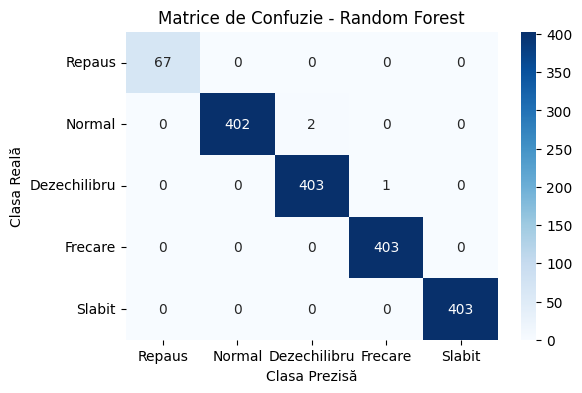


=== Antrenare SVM ===
              precision    recall  f1-score   support

      Repaus       1.00      0.99      0.99        67
      Normal       1.00      1.00      1.00       404
Dezechilibru       0.99      1.00      0.99       404
     Frecare       1.00      1.00      1.00       403
      Slabit       1.00      0.99      0.99       403

    accuracy                           1.00      1681
   macro avg       1.00      0.99      1.00      1681
weighted avg       1.00      1.00      1.00      1681



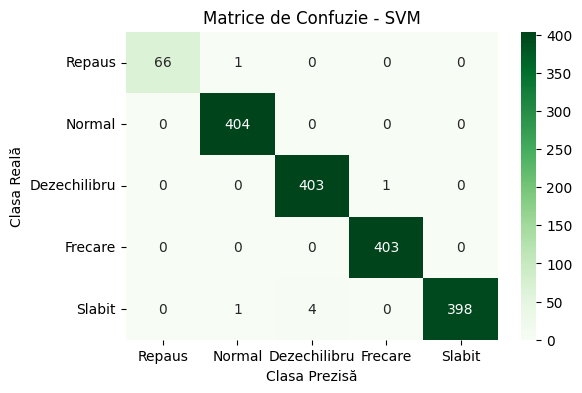


=== Antrenare K-Means (Pe Caracteristici Extrase) ===
Timp antrenare K-Means: 1.67 secunde

Raport de clasificare K-Means:
              precision    recall  f1-score   support

      Repaus       1.00      0.99      0.99        67
      Normal       0.67      0.76      0.71       404
Dezechilibru       0.75      0.79      0.77       404
     Frecare       1.00      0.83      0.91       403
      Slabit       1.00      0.99      0.99       403

    accuracy                           0.85      1681
   macro avg       0.88      0.87      0.88      1681
weighted avg       0.86      0.85      0.85      1681



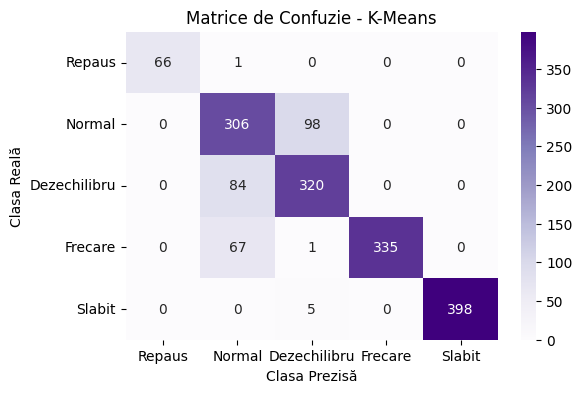

In [8]:
import numpy as np
from scipy.stats import skew, kurtosis
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import time
from collections import Counter

# ==========================================
# 0. Funcția de Extragere a Caracteristicilor
# ==========================================
def extract_statistical_features(X_3D):
    """
    Transformă datele 3D (ferestre, 128, 6) în 2D (ferestre, 30)
    extrăgând 5 caracteristici statistice per senzor, cu protecție la împărțirea la zero.
    """
    num_windows = X_3D.shape[0]
    num_sensors = X_3D.shape[2]
    
    X_features = np.zeros((num_windows, num_sensors * 5))
    
    for i in range(num_windows):
        col_idx = 0
        for s in range(num_sensors):
            sensor_data = X_3D[i, :, s]
            
            mean_val = np.mean(sensor_data)
            std_val = np.std(sensor_data)
            
            X_features[i, col_idx] = mean_val
            X_features[i, col_idx+1] = std_val
            X_features[i, col_idx+2] = np.sqrt(np.mean(sensor_data**2))
            
            if std_val < 1e-5:
                X_features[i, col_idx+3] = 0.0
                X_features[i, col_idx+4] = 0.0
            else:
                X_features[i, col_idx+3] = skew(sensor_data)
                X_features[i, col_idx+4] = kurtosis(sensor_data)
            
            col_idx += 5
            
    X_features = np.nan_to_num(X_features, nan=0.0, posinf=0.0, neginf=0.0)
    return X_features

# ==========================================
# 1. Aplicarea funcției pe date
# ==========================================
print("Extragere caracteristici din datele de Train...")
start_time = time.time()
X_train_features = extract_statistical_features(X_train)
print(f"Timp extragere Train: {time.time() - start_time:.2f} secunde")

print("Extragere caracteristici din datele de Test...")
X_test_features = extract_statistical_features(X_test)

class_names_str = ['Repaus', 'Normal', 'Dezechilibru', 'Frecare', 'Slabit']

# ==========================================
# 2. Random Forest
# ==========================================
print("\n=== Antrenare Random Forest ===")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_features, y_train)

rf_preds = rf_model.predict(X_test_features)
print(classification_report(y_test, rf_preds, target_names=class_names_str))

cm_rf = confusion_matrix(y_test, rf_preds)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', xticklabels=class_names_str, yticklabels=class_names_str)
plt.title('Matrice de Confuzie - Random Forest')
plt.ylabel('Clasa Reală')
plt.xlabel('Clasa Prezisă')
plt.show()

# ==========================================
# 3. SVM (LinearSVC)
# ==========================================
print("\n=== Antrenare SVM ===")
# Scalăm datele (foarte important pentru SVM și K-Means)
scaler = StandardScaler()
X_train_features_scaled = scaler.fit_transform(X_train_features)
X_test_features_scaled = scaler.transform(X_test_features)

svm_model = LinearSVC(random_state=42, max_iter=3000, dual=False)
svm_model.fit(X_train_features_scaled, y_train)

svm_preds = svm_model.predict(X_test_features_scaled)
print(classification_report(y_test, svm_preds, target_names=class_names_str))

cm_svm = confusion_matrix(y_test, svm_preds)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens', xticklabels=class_names_str, yticklabels=class_names_str)
plt.title('Matrice de Confuzie - SVM')
plt.ylabel('Clasa Reală')
plt.xlabel('Clasa Prezisă')
plt.show()

# ==========================================
# 4. K-Means Clustering (Nesupervizat cu Mapare)
# ==========================================
print("\n=== Antrenare K-Means (Pe Caracteristici Extrase) ===")
# Folosim datele STANDARDizate (X_train_features_scaled) pentru K-Means
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

start_time = time.time()
kmeans.fit(X_train_features_scaled)
print(f"Timp antrenare K-Means: {time.time() - start_time:.2f} secunde")

# 1. Obținem clusterele pe train și test (Folosind Features Standardizate!)
train_clusters = kmeans.predict(X_train_features_scaled)
test_clusters = kmeans.predict(X_test_features_scaled)

# 2. Mapăm fiecare cluster la cea mai frecventă clasă reală
cluster_mapping = {}
y_train_np = np.array(y_train) 

for i in range(5):
    indices_in_cluster = np.where(train_clusters == i)[0]
    
    if len(indices_in_cluster) > 0:
        true_labels = y_train_np[indices_in_cluster]
        most_common_label = Counter(true_labels).most_common(1)[0][0]
        cluster_mapping[i] = most_common_label
    else:
        cluster_mapping[i] = 0 # Fallback

# 3. Transformăm clusterele prezise pe setul de test în etichete reale mapate
kmeans_preds = np.array([cluster_mapping[c] for c in test_clusters])

# 4. Afișăm rezultatele
print("\nRaport de clasificare K-Means:")
print(classification_report(y_test, kmeans_preds, target_names=class_names_str, zero_division=0))

cm_kmeans = confusion_matrix(y_test, kmeans_preds)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_kmeans, annot=True, fmt='d', cmap='Purples', xticklabels=class_names_str, yticklabels=class_names_str)
plt.title('Matrice de Confuzie - K-Means')
plt.ylabel('Clasa Reală')
plt.xlabel('Clasa Prezisă')
plt.show()


Modelul CNN 2D a fost salvat ca: model_cnn2d_original.keras
Modelul CNN 3D a fost salvat ca: model_cnn3d_original.keras



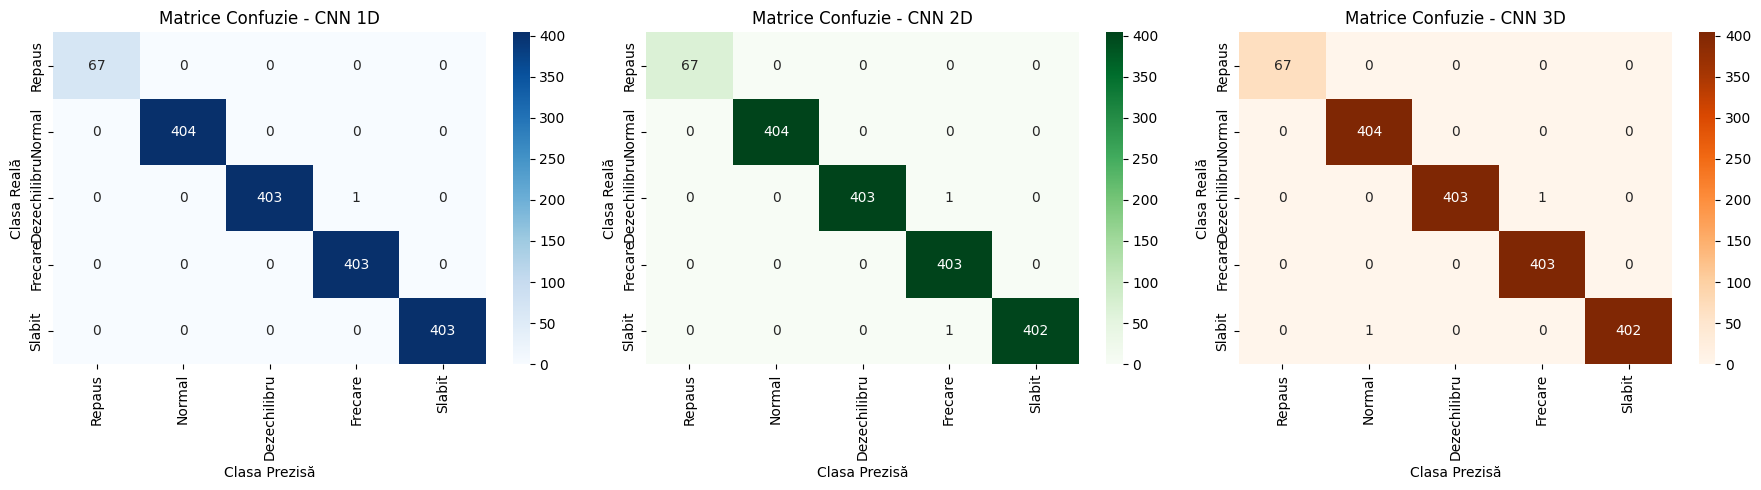


=== Raport Clasificare - CNN 1D ===
              precision    recall  f1-score   support

      Repaus       1.00      1.00      1.00        67
      Normal       1.00      1.00      1.00       404
Dezechilibru       1.00      1.00      1.00       404
     Frecare       1.00      1.00      1.00       403
      Slabit       1.00      1.00      1.00       403

    accuracy                           1.00      1681
   macro avg       1.00      1.00      1.00      1681
weighted avg       1.00      1.00      1.00      1681


=== Raport Clasificare - CNN 2D ===
              precision    recall  f1-score   support

      Repaus       1.00      1.00      1.00        67
      Normal       1.00      1.00      1.00       404
Dezechilibru       1.00      1.00      1.00       404
     Frecare       1.00      1.00      1.00       403
      Slabit       1.00      1.00      1.00       403

    accuracy                           1.00      1681
   macro avg       1.00      1.00      1.00      1681
wei

In [9]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tensorflow as tf

# 1. Salvare modele 2D și 3D (format .keras)
model = tf.keras.models.load_model("model_cnn1d_original.keras") # Asigură-te că modelul 1D este încărcat pentru comparație
model_2d = tf.keras.models.load_model("model_cnn2d_original.keras")
print("Modelul CNN 2D a fost salvat ca: model_cnn2d_original.keras")

model_3d = tf.keras.models.load_model("model_cnn3d_original.keras")
print("Modelul CNN 3D a fost salvat ca: model_cnn3d_original.keras\n")

# Numele claselor pentru grafice
class_names = ['Repaus', 'Normal', 'Dezechilibru', 'Frecare', 'Slabit']
X_train_2d = np.expand_dims(X_train, axis=-1)
X_test_2d = np.expand_dims(X_test, axis=-1)
X_train_3d = X_train.reshape(-1, 128, 2, 3, 1)
X_test_3d = X_test.reshape(-1, 128, 2, 3, 1)
# 2. Obținem predicțiile pentru fiecare model pe setul de test
# verbose=0 ascunde bara de progres la predictie
y_pred_1d = np.argmax(model.predict(X_test, verbose=0), axis=1)
y_pred_2d = np.argmax(model_2d.predict(X_test_2d, verbose=0), axis=1)
y_pred_3d = np.argmax(model_3d.predict(X_test_3d, verbose=0), axis=1)

# 3. Calculăm matricile de confuzie
cm_1d = confusion_matrix(y_test, y_pred_1d)
cm_2d = confusion_matrix(y_test, y_pred_2d)
cm_3d = confusion_matrix(y_test, y_pred_3d)

# 4. Plotare comparativă a matricilor de confuzie (1 rând, 3 coloane)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Matrice pentru CNN 1D
sns.heatmap(cm_1d, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Matrice Confuzie - CNN 1D')
axes[0].set_ylabel('Clasa Reală')
axes[0].set_xlabel('Clasa Prezisă')

# Matrice pentru CNN 2D
sns.heatmap(cm_2d, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Matrice Confuzie - CNN 2D')
axes[1].set_ylabel('Clasa Reală')
axes[1].set_xlabel('Clasa Prezisă')

# Matrice pentru CNN 3D
sns.heatmap(cm_3d, annot=True, fmt='d', cmap='Oranges', xticklabels=class_names, yticklabels=class_names, ax=axes[2])
axes[2].set_title('Matrice Confuzie - CNN 3D')
axes[2].set_ylabel('Clasa Reală')
axes[2].set_xlabel('Clasa Prezisă')

plt.tight_layout()
plt.show()

# 5. Afișare rapoarte de clasificare detaliate
print("\n=== Raport Clasificare - CNN 1D ===")
print(classification_report(y_test, y_pred_1d, target_names=class_names))

print("\n=== Raport Clasificare - CNN 2D ===")
print(classification_report(y_test, y_pred_2d, target_names=class_names))

print("\n=== Raport Clasificare - CNN 3D ===")
print(classification_report(y_test, y_pred_3d, target_names=class_names))


Shape features train: (6727, 18)
Shape features test:  (1681, 18)

Timp antrenare RF: 0.17s

Timp antrenare RF: 0.18s
Timp inferență total (1681 ferestre): 28.7 ms
Timp inferență per fereastră: 0.0171 ms

=== Raport Clasificare - Random Forest (Mean+Std+RMS) ===
              precision    recall  f1-score   support

      Repaus       1.00      0.99      0.99        67
      Normal       1.00      1.00      1.00       404
Dezechilibru       1.00      1.00      1.00       404
     Frecare       1.00      1.00      1.00       403
      Slabit       1.00      1.00      1.00       403

    accuracy                           1.00      1681
   macro avg       1.00      1.00      1.00      1681
weighted avg       1.00      1.00      1.00      1681



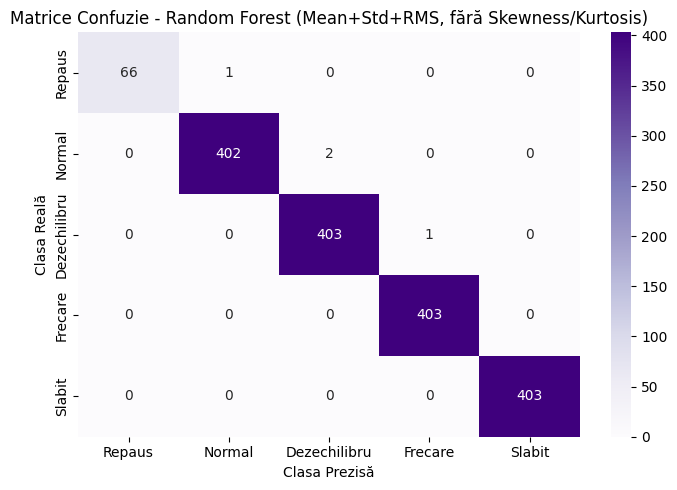


=== REZUMAT COMPARATIV ===
Model                          Accuracy     Inf/fereastră (ms)
-------------------------------------------------------
Random Forest (18 features)    0.9976       0.0171
CNN 1D (end-to-end)            0.9994       0.1111

Notă: timpii de mai sus sunt pe PC (CPU). Pe ESP32 vor fi radical diferiți.
CNN 1D avantaj: nu necesită feature engineering în C++ pe device.


In [10]:
"""
Adaugă această celulă în notebook-ul tău după Celula 3 (create_windows).
X_train shape: (6727, 128, 6)
X_test shape:  (1681, 128, 6)
y_train, y_test: deja disponibile
"""

import numpy as np
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ── 1. Feature extraction: Mean + Std + RMS per axă (18 features total) ──────

def extract_features_reduced(X_windows):
    """
    X_windows: (n_samples, 128, 6)
    Returnează: (n_samples, 18)  →  mean(6) + std(6) + rms(6)
    """
    mean = X_windows.mean(axis=1)                          # (n, 6)
    std  = X_windows.std(axis=1)                           # (n, 6)
    rms  = np.sqrt((X_windows ** 2).mean(axis=1))          # (n, 6)
    return np.hstack([mean, std, rms])                     # (n, 18)

X_train_rf = extract_features_reduced(X_train)
X_test_rf  = extract_features_reduced(X_test)

print(f"Shape features train: {X_train_rf.shape}")   # (6727, 18)
print(f"Shape features test:  {X_test_rf.shape}")    # (1681, 18)

# ── 2. Antrenare Random Forest ────────────────────────────────────────────────

# 1. Definim manual ponderile (Class Weights)
# Presupunând că etichetele sunt: 0=Repaus, 1=Normal, 2=Dezechilibru, 3=Frecare, 4=Slabit
# IMPORTANT: Verifică în codul tău care număr corespunde Dezechilibrului (aici presupunem 2, bazat pe raportul tău anterior, dar ajustează dacă e 3).
ponderi_personalizate = {
    0: 1.0,   # Repaus
    1: 2.0,   # Normal (îl forțăm să aleagă Normal mai des)
    2: 0.8,   # Dezechilibru (Pondere extrem de mică! Va evita să o aleagă dacă nu e 100% sigur)
    3: 2.0,   # Frecare (Pondere masivă pentru a o detecta mai bine)
    4: 1.0    # Slabit
}

# 2. Antrenăm modelul cu regularizare agresivă
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,                 # SCĂZUT de la 10 la 5. Îl forțează să facă reguli mai generale, nu limite rigide.
    min_samples_split=12,        # Creștem numărul necesar pentru o ramificare
    min_samples_leaf=12,         # Reguli mai "groase", previne overfitting-ul pe zgomot
    max_features='sqrt',
    random_state=42,
    class_weight=ponderi_personalizate, # Folosim dicționarul
    n_jobs=-1
)

t0 = time.perf_counter()
rf.fit(X_train_rf, y_train)
train_time = time.perf_counter() - t0
print(f"\nTimp antrenare RF: {train_time:.2f}s")

t0 = time.perf_counter()
rf.fit(X_train_rf, y_train)
train_time = time.perf_counter() - t0
print(f"\nTimp antrenare RF: {train_time:.2f}s")

# ── 3. Evaluare + timp inferență per fereastră ────────────────────────────────

t0 = time.perf_counter()
y_pred_rf = rf.predict(X_test_rf)
inference_total = time.perf_counter() - t0
inference_per_window_ms = (inference_total / len(X_test_rf)) * 1000

print(f"Timp inferență total ({len(X_test_rf)} ferestre): {inference_total*1000:.1f} ms")
print(f"Timp inferență per fereastră: {inference_per_window_ms:.4f} ms")

class_names = ['Repaus', 'Normal', 'Dezechilibru', 'Frecare', 'Slabit']

print("\n=== Raport Clasificare - Random Forest (Mean+Std+RMS) ===")
print(classification_report(y_test, y_pred_rf, target_names=class_names))

# ── 4. Matrice confuzie ───────────────────────────────────────────────────────

cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Purples',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matrice Confuzie - Random Forest (Mean+Std+RMS, fără Skewness/Kurtosis)')
plt.ylabel('Clasa Reală')
plt.xlabel('Clasa Prezisă')
plt.tight_layout()
plt.show()

# ── 5. Rezumat comparativ cu CNN 1D ──────────────────────────────────────────

print("\n=== REZUMAT COMPARATIV ===")
print(f"{'Model':<30} {'Accuracy':<12} {'Inf/fereastră (ms)'}")
print("-" * 55)

# CNN 1D - timpul de inferență pe PC (din notebook dacă ai măsurat, altfel estimat)
# Înlocuiește cu valoarea reală dacă o ai
import tensorflow as tf
model_cnn = tf.keras.models.load_model("model_cnn1d_original.keras")
t0 = time.perf_counter()
_ = model_cnn.predict(X_test, verbose=0)
cnn_inf_ms = (time.perf_counter() - t0) / len(X_test) * 1000

from sklearn.metrics import accuracy_score
acc_rf  = accuracy_score(y_test, y_pred_rf)
acc_cnn = accuracy_score(y_test, np.argmax(model_cnn.predict(X_test, verbose=0), axis=1))

print(f"{'Random Forest (18 features)':<30} {acc_rf:.4f}       {inference_per_window_ms:.4f}")
print(f"{'CNN 1D (end-to-end)':<30} {acc_cnn:.4f}       {cnn_inf_ms:.4f}")
print()
print("Notă: timpii de mai sus sunt pe PC (CPU). Pe ESP32 vor fi radical diferiți.")
print("CNN 1D avantaj: nu necesită feature engineering în C++ pe device.")

In [13]:
# pip install micromlgen  (rulează o dată în terminal)
from micromlgen import port

# Generează codul C++ pentru RF
c_code = port(rf, classname='MotorClassifier')

# Salvează în fișier
with open('motor_classifier.h', 'w') as f:
    f.write(c_code)

print("Fișierul motor_classifier.h a fost generat!")
print(f"Primele 500 caractere:\n{c_code[:500]}")

Fișierul motor_classifier.h a fost generat!
Primele 500 caractere:
#pragma once
#include <cstdarg>
namespace Eloquent {
    namespace ML {
        namespace Port {
            class MotorClassifier {
                public:
                    /**
                    * Predict class for features vector
                    */
                    int predict(float *x) {
                        uint8_t votes[5] = { 0 };
                        // tree #1
                        if (x[13] <= 0.8214789628982544) {
                            if (x[14] <= 0.962263673


In [6]:
import pandas as pd

df = pd.read_csv('dataset_final.csv')
print(df.groupby('label').size())
# sau dacă ai și nume
print(df[['label']].value_counts().sort_index())

label
0     21536
1    129216
2    129216
3    129215
4    129144
dtype: int64
label
0         21536
1        129216
2        129216
3        129215
4        129144
Name: count, dtype: int64


In [8]:
# Verifică ce label ai dat fiecărei clase când ai colectat datele
print(df[df['label'] == 2]['pwm_speed'].head(10))
# sau dacă ai o coloană cu numele clasei
print(df.columns.tolist())
# Uită-te la caracteristicile statistice per clasă
print(df.groupby('label')[['ax','ay','az']].std())

0    160
1    160
2    160
3    160
4    160
5    160
6    160
7    160
8    160
9    160
Name: pwm_speed, dtype: int64
['ax', 'ay', 'az', 'gx', 'gy', 'gz', 'temp', 'label', 'pwm_speed']
             ax        ay        az
label                              
0      0.011779  0.010599  0.020623
1      0.245933  0.142243  0.165822
2      0.267827  0.204369  0.303884
3      0.369930  0.265968  0.358331
4      0.261320  0.193313  0.127534
